**TASK 1 - DATA PREPARATION**

In [ ]:

### TASK 1 – DATA PREPARATION

### 1 – Import Libraries


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow Version: 2.21.0
Libraries imported successfully!


In [ ]:
### Step 2 – Load Dataset

(X_train, y_train), (X_test, y_test) = cifar10.load_data()

print("Dataset loaded successfully!")
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Dataset loaded successfully!
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [ ]:
### 3 – Explore Dataset

class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

print("Number of training images:", len(X_train))
print("Number of testing images:", len(X_test))
print("Number of classes:", len(class_names))
print("Class names:", class_names)

print("\nFirst 10 labels:")
print(y_train[:10].flatten())

Number of training images: 50000
Number of testing images: 10000
Number of classes: 10
Class names: ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer', 'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

First 10 labels:
[6 9 9 4 1 1 2 7 8 3]


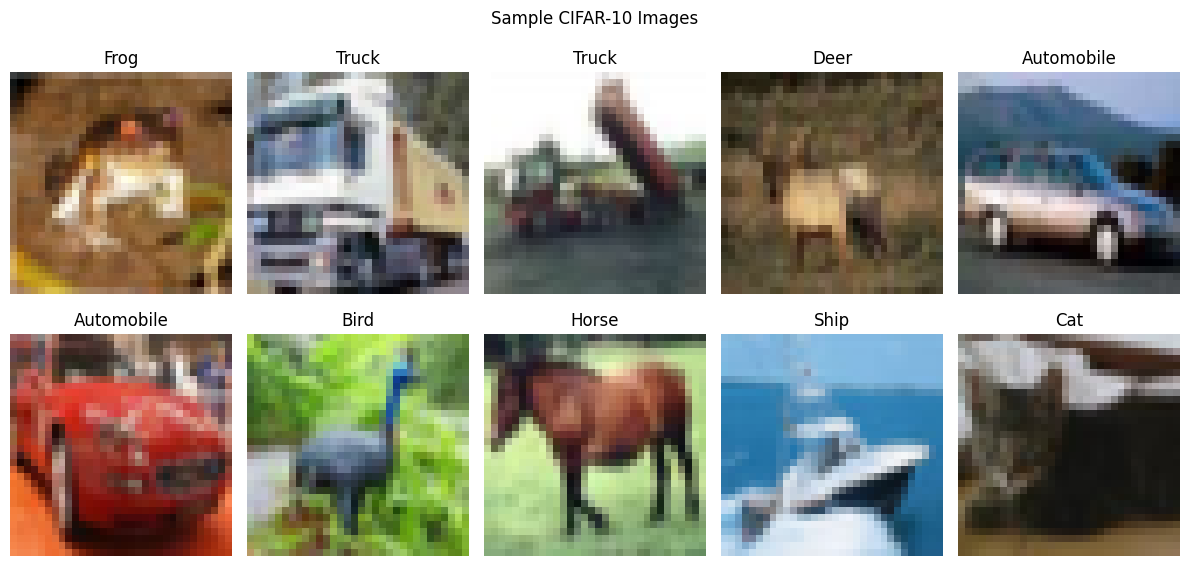

In [ ]:
###  4 – Visualize Sample Images


plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis('off')

plt.suptitle("Sample CIFAR-10 Images")
plt.tight_layout()
plt.show()

In [ ]:
###  5 – Normalize Images


X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Image normalization completed!")
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Image normalization completed!
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [ ]:
###  6 – Train and Validation Split

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train.flatten()
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 32, 32, 3)
Validation data: (10000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [ ]:
### 7 – Convert Labels into Categorical Format

y_train_cat = to_categorical(y_train, 10)
y_val_cat = to_categorical(y_val, 10)
y_test_cat = to_categorical(y_test, 10)

print("Label conversion completed!")
print("Training labels:", y_train_cat.shape)
print("Validation labels:", y_val_cat.shape)
print("Testing labels:", y_test_cat.shape)



Label conversion completed!
Training labels: (40000, 10)
Validation labels: (10000, 10)
Testing labels: (10000, 10)


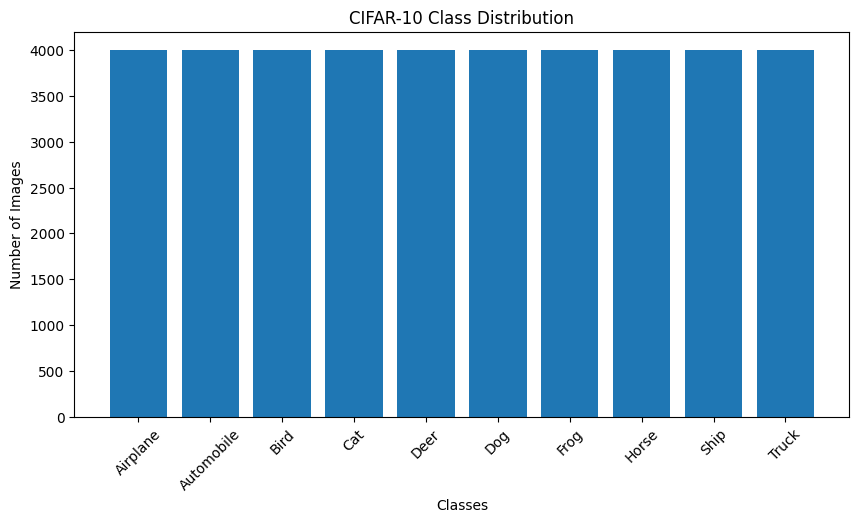

In [ ]:
###  8 – Class Distribution


unique, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(10, 5))
plt.bar(
    [class_names[int(i)] for i in unique],
    counts
)
plt.title("CIFAR-10 Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

**TASK** **2** – **CNN** **MODEL** **DEVELOPMENT**

In [ ]:
cnn_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(10, activation='softmax')
])

print("CNN Model Created Successfully!")


CNN Model Created Successfully!


In [ ]:
###  10 – Display CNN Architecture
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
###  11 – Compile CNN Model

cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [ ]:
###  12 – Train CNN Model

cnn_history = cnn_model.fit(
   X_train,
    y_train_cat,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val_cat),
    verbose=1
)

print("CNN Training Completed!")

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 98s 152ms/step - accuracy: 0.3759 - loss: 1.7027 - val_accuracy: 0.5141 - val_loss: 1.3322
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 142s 153ms/step - accuracy: 0.5301 - loss: 1.3115 - val_accuracy: 0.6208 - val_loss: 1.0880
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 142s 154ms/step - accuracy: 0.6039 - loss: 1.1265 - val_accuracy: 0.6681 - val_loss: 0.9467
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 91s 145ms/step - accuracy: 0.6528 - loss: 0.9985 - val_accuracy: 0.6877 - val_loss: 0.8824
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 89s 143ms/step - accuracy: 0.6830 - loss: 0.9060 - val_accuracy: 0.6772 - val_loss: 0.9117
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 96s 153ms/step - accuracy: 0.7073 - loss: 0.8416 - val_accuracy: 0.7247 - val_loss: 0.7890
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 91s 145ms/step - accuracy: 0.7303 - loss: 0.7758 - val_accuracy: 0.7279 - val_loss: 0.7894
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 91s 145ms/step - accuracy: 0.7483 - loss:

In [ ]:
###  13 – Evaluate CNN Model


cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_test,
    y_test_cat,
    verbose=1
)

print("CNN Test Loss:", cnn_loss)
print("CNN Test Accuracy:", cnn_accuracy)
print("CNN Test Accuracy (%):", cnn_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.7405 - loss: 0.7819
CNN Test Loss: 0.7819278836250305
CNN Test Accuracy: 0.7404999732971191
CNN Test Accuracy (%): 74.04999732971191


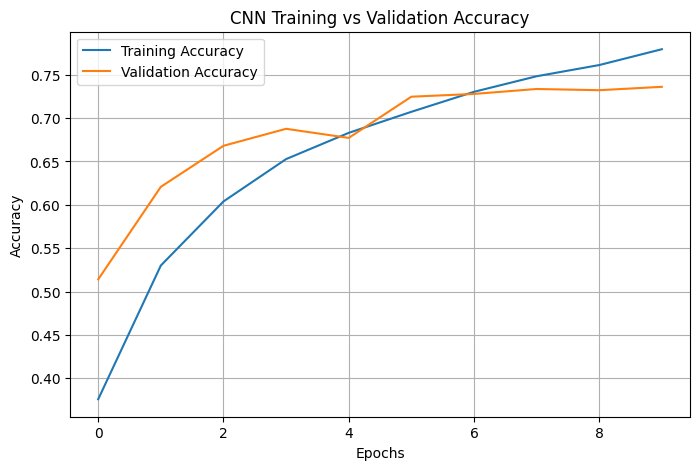

In [ ]:
### 14 – CNN Accuracy Graph


plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history['accuracy'], label='Training Accuracy')
plt.plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')

plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

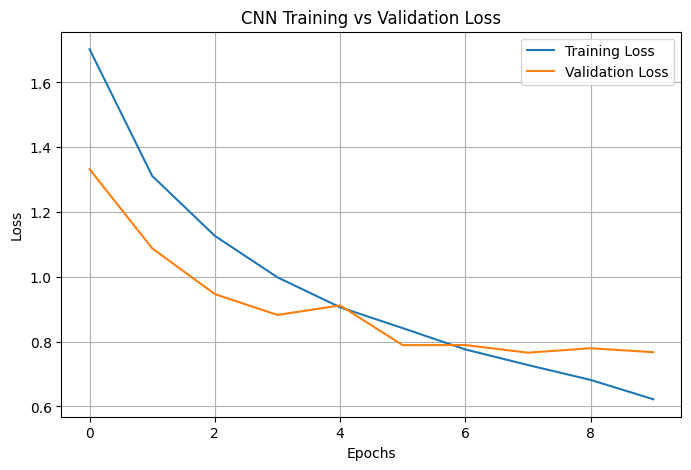

In [ ]:
###  15 – CNN Loss Graph

plt.figure(figsize=(8, 5))

plt.plot(cnn_history.history['loss'], label='Training Loss')
plt.plot(cnn_history.history['val_loss'], label='Validation Loss')

plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


In [ ]:
### 16 – CNN Predictions

cnn_predictions = cnn_model.predict(X_test, verbose=1)

cnn_predicted_labels = np.argmax(cnn_predictions, axis=1)
actual_labels = y_test.flatten()

print("CNN Predictions Generated!")
print("First 10 Actual Labels:")
print(actual_labels[:10])

print("First 10 Predicted Labels:")
print(cnn_predicted_labels[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step
CNN Predictions Generated!
First 10 Actual Labels:
[3 8 8 0 6 6 1 6 3 1]
First 10 Predicted Labels:
[3 8 8 0 6 6 1 2 3 1]


In [ ]:
###  17 – CNN Classification Report

print("CNN Classification Report")

print(classification_report(
    actual_labels,
    cnn_predicted_labels,
    target_names=class_names
))

CNN Classification Report
              precision    recall  f1-score   support

    Airplane       0.78      0.80      0.79      1000
  Automobile       0.83      0.89      0.86      1000
        Bird       0.57      0.68      0.62      1000
         Cat       0.56      0.56      0.56      1000
        Deer       0.72      0.66      0.69      1000
         Dog       0.73      0.53      0.62      1000
        Frog       0.69      0.88      0.78      1000
       Horse       0.85      0.76      0.80      1000
        Ship       0.88      0.84      0.86      1000
       Truck       0.86      0.80      0.83      1000

    accuracy                           0.74     10000
   macro avg       0.75      0.74      0.74     10000
weighted avg       0.75      0.74      0.74     10000



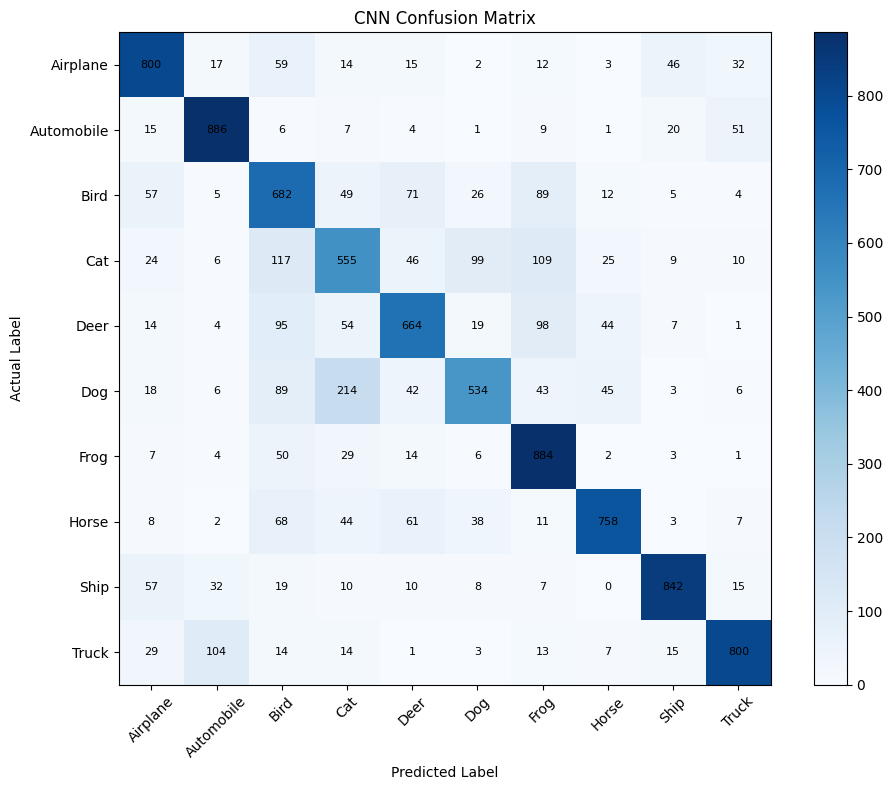

In [ ]:
### 18 – CNN Confusion Matrix


cm_cnn = confusion_matrix(
    actual_labels,
    cnn_predicted_labels
)

plt.figure(figsize=(10, 8))
plt.imshow(cm_cnn, cmap='Blues')
plt.colorbar()

plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("CNN Confusion Matrix")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm_cnn[i, j],
                 ha='center', va='center', fontsize=8)

plt.tight_layout()
plt.show()

**TASK** **3** – **TRANSFER** **LEARNING** **USING** **MOBILENETV2**

In [ ]:
### 19 – Import MobileNetV2

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

print("MobileNetV2 imported successfully!")

MobileNetV2 imported successfully!


In [ ]:
###  20 – Load Pretrained MobileNetV2

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

print("Pretrained MobileNetV2 loaded!")
print("Base model layers:", len(base_model.layers))

Pretrained MobileNetV2 loaded!
Base model layers: 154


In [ ]:
### 21 – Build MobileNetV2 Model

mobilenet_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Resizing(96, 96),

    layers.Lambda(preprocess_input),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.3),

    layers.Dense(10, activation='softmax')
])

print("MobileNetV2 Model Created Successfully!")

MobileNetV2 Model Created Successfully!


In [ ]:
###  22 – Display Model Summary


mobilenet_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
### 23 – Compile MobileNetV2

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("MobileNetV2 Compiled Successfully!")

MobileNetV2 Compiled Successfully!


In [ ]:
### 24 – Train MobileNetV2

mobilenet_history = mobilenet_model.fit(
    X_train,
    y_train_cat,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val_cat),
    verbose=1
)

print("MobileNetV2 Training Completed!")

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 342s 538ms/step - accuracy: 0.0956 - loss: 2.3099 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 397s 564ms/step - accuracy: 0.0987 - loss: 2.3028 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 349s 559ms/step - accuracy: 0.0983 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 331s 529ms/step - accuracy: 0.0999 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 337s 540ms/step - accuracy: 0.0987 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
MobileNetV2 Training Completed!


In [ ]:
###  25 – Evaluate MobileNetV2



mobilenet_loss, mobilenet_accuracy = mobilenet_model.evaluate(
    X_test,
    y_test_cat,
    verbose=1
)

print("MobileNetV2 Test Loss:", mobilenet_loss)
print("MobileNetV2 Test Accuracy:", mobilenet_accuracy)
print("MobileNetV2 Accuracy (%):", mobilenet_accuracy * 100)


313/313 ━━━━━━━━━━━━━━━━━━━━ 64s 203ms/step - accuracy: 0.1000 - loss: 2.3026
MobileNetV2 Test Loss: 2.3026230335235596
MobileNetV2 Test Accuracy: 0.10000000149011612
MobileNetV2 Accuracy (%): 10.000000149011612


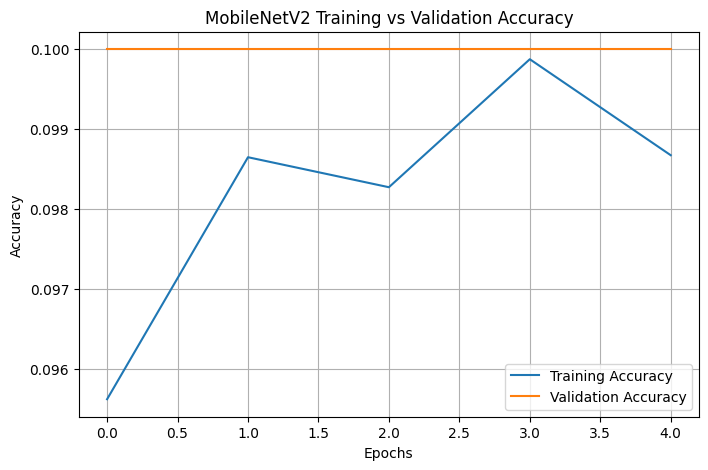

In [ ]:
## 26 – MobileNetV2 Accuracy Graph


plt.figure(figsize=(8, 5))

plt.plot(
    mobilenet_history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    mobilenet_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("MobileNetV2 Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

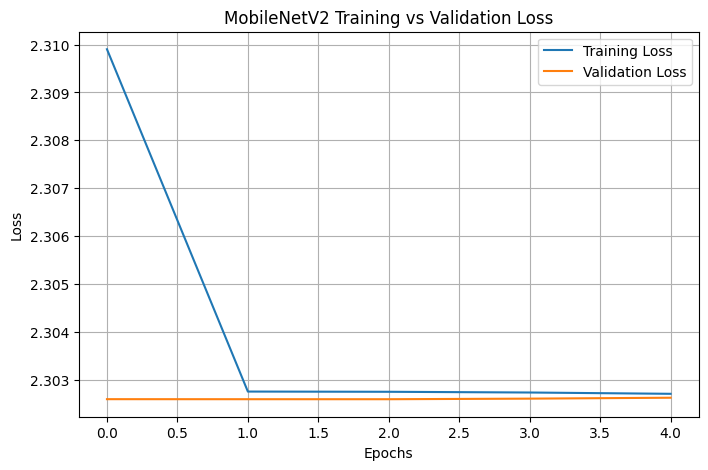

In [ ]:
###  27 – MobileNetV2 Loss Graph


plt.figure(figsize=(8, 5))

plt.plot(
    mobilenet_history.history['loss'],
    label='Training Loss'
)

plt.plot(
    mobilenet_history.history['val_loss'],
    label='Validation Loss'
)

plt.title("MobileNetV2 Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


In [ ]:
##  28 – MobileNetV2 Predictions



mobilenet_predictions = mobilenet_model.predict(
    X_test,
    verbose=1
)

mobilenet_predicted_labels = np.argmax(
    mobilenet_predictions,
    axis=1
)

print("MobileNetV2 Predictions Generated!")

print("Actual Labels:")
print(actual_labels[:10])

print("Predicted Labels:")
print(mobilenet_predicted_labels[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 66s 206ms/step
MobileNetV2 Predictions Generated!
Actual Labels:
[3 8 8 0 6 6 1 6 3 1]
Predicted Labels:
[1 1 1 1 1 1 1 1 1 1]


In [ ]:
##  29 – MobileNetV2 Classification Report



print("MobileNetV2 Classification Report")

print(classification_report(
    actual_labels,
    mobilenet_predicted_labels,
    target_names=class_names
))


MobileNetV2 Classification Report
              precision    recall  f1-score   support

    Airplane       0.00      0.00      0.00      1000
  Automobile       0.10      1.00      0.18      1000
        Bird       0.00      0.00      0.00      1000
         Cat       0.00      0.00      0.00      1000
        Deer       0.00      0.00      0.00      1000
         Dog       0.00      0.00      0.00      1000
        Frog       0.00      0.00      0.00      1000
       Horse       0.00      0.00      0.00      1000
        Ship       0.00      0.00      0.00      1000
       Truck       0.00      0.00      0.00      1000

    accuracy                           0.10     10000
   macro avg       0.01      0.10      0.02     10000
weighted avg       0.01      0.10      0.02     10000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


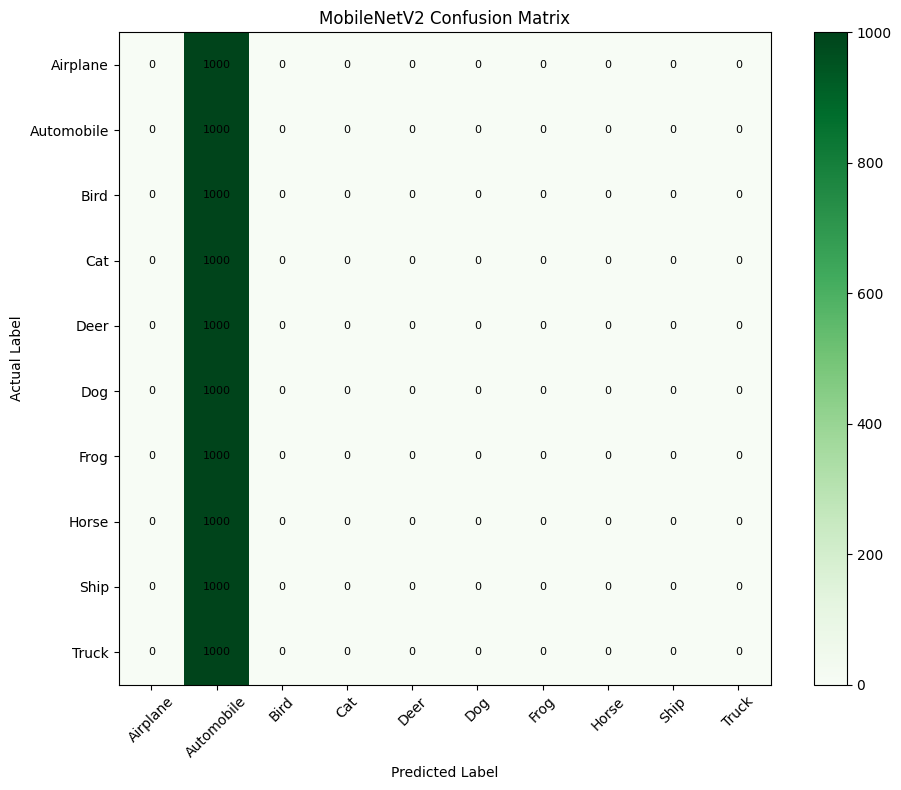

In [ ]:
## 30 – MobileNetV2 Confusion Matrix

cm_mobile = confusion_matrix(
    actual_labels,
    mobilenet_predicted_labels
)

plt.figure(figsize=(10, 8))
plt.imshow(cm_mobile, cmap='Greens')
plt.colorbar()

plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("MobileNetV2 Confusion Matrix")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm_mobile[i, j],
                 ha='center', va='center', fontsize=8)

plt.tight_layout()
plt.show()

         Model  Test Accuracy  Test Loss
0   Custom CNN         0.7405   0.781928
1  MobileNetV2         0.1000   2.302623


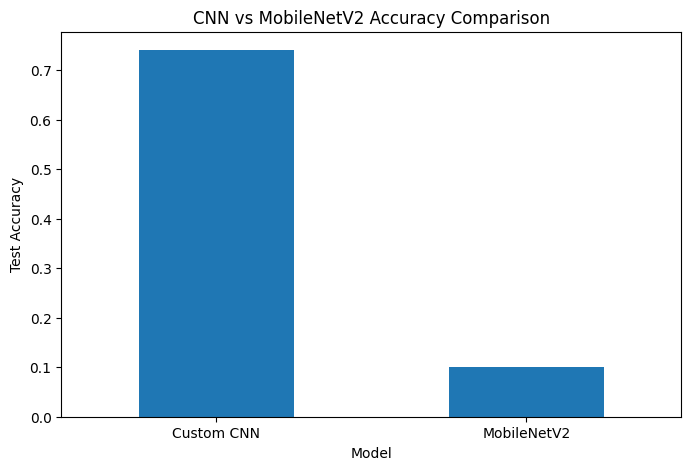

In [ ]:
### 31 – Compare CNN and MobileNetV2


comparison = pd.DataFrame({
    'Model': ['Custom CNN', 'MobileNetV2'],
    'Test Accuracy': [cnn_accuracy, mobilenet_accuracy],
    'Test Loss': [cnn_loss, mobilenet_loss]
})

print(comparison)

comparison.plot(
    x='Model',
    y='Test Accuracy',
    kind='bar',
    legend=False,
    figsize=(8, 5)
)

plt.title("CNN vs MobileNetV2 Accuracy Comparison")
plt.ylabel("Test Accuracy")
plt.xticks(rotation=0)
plt.show()

**TASK-4 PREDICTION AND VISUALIZATION**

In [ ]:
# TASK 4 - PREDICTION AND VISUALIZATION

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
#  DEFINE CLASS NAMES
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

Actual Class: Airplane
Predicted Class: Automobile
Prediction Confidence: 10.15 %


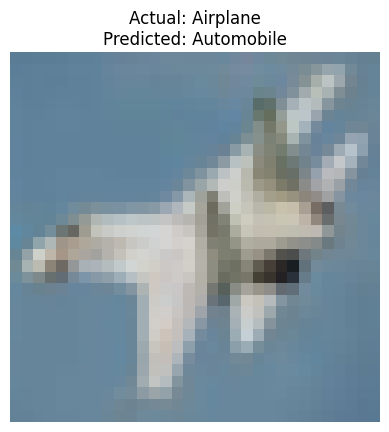

In [ ]:
###  32 – Predict Unseen Images

sample_index = 10

image = X_test[sample_index]

prediction = mobilenet_model.predict(
    np.expand_dims(image, axis=0),
    verbose=0
)

predicted_class = np.argmax(prediction)
actual_class = int(y_test[sample_index][0])

print("Actual Class:", class_names[actual_class])
print("Predicted Class:", class_names[predicted_class])
print("Prediction Confidence:",
      round(float(np.max(prediction)) * 100, 2), "%")

plt.imshow(image)
plt.title(
    f"Actual: {class_names[actual_class]}\n"
    f"Predicted: {class_names[predicted_class]}"
)
plt.axis('off')
plt.show()

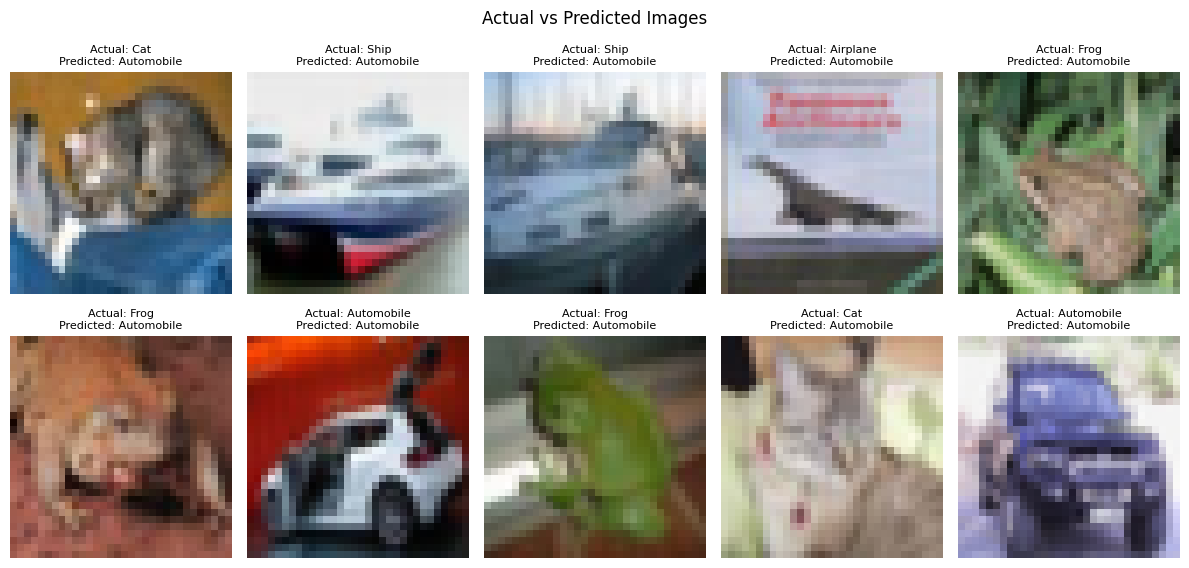

In [ ]:
### 3 – Display Actual vs Predicted Labels


plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i])

    actual = class_names[int(y_test[i][0])]
    predicted = class_names[int(mobilenet_predicted_labels[i])]

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=8
    )

    plt.axis('off')

plt.suptitle("Actual vs Predicted Images")
plt.tight_layout()
plt.show()

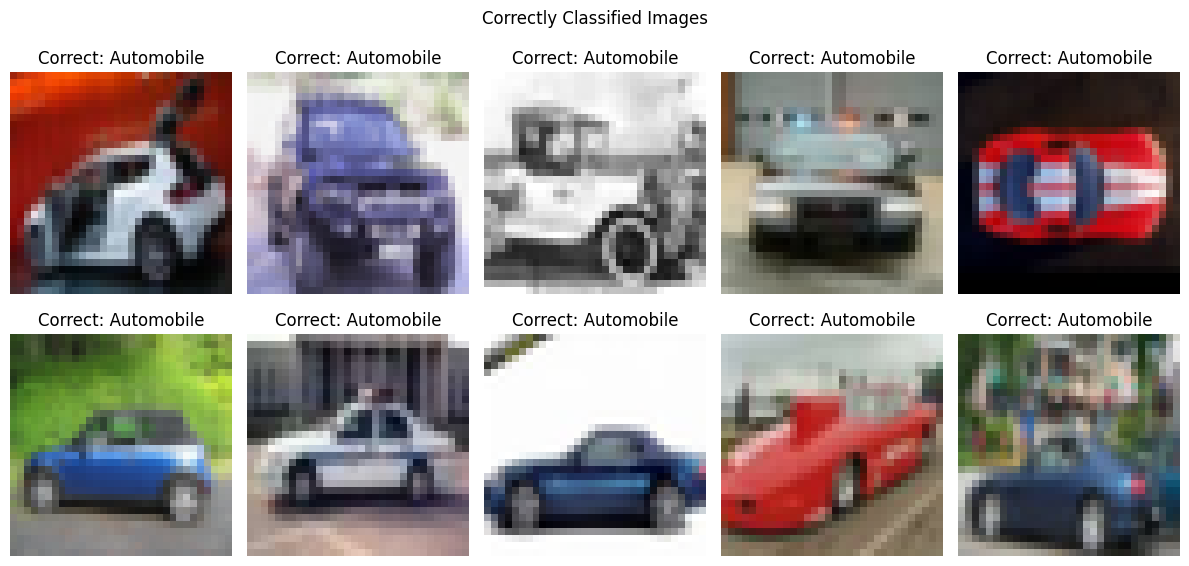

Total Correct Predictions: 1000


In [ ]:
###  34 – Visualize Correctly Classified Images


correct_indices = np.where(
    mobilenet_predicted_labels == actual_labels
)[0]

plt.figure(figsize=(12, 6))

for i, idx in enumerate(correct_indices[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[idx])

    plt.title(
        "Correct: " +
        class_names[mobilenet_predicted_labels[idx]]
    )

    plt.axis('off')

plt.suptitle("Correctly Classified Images")
plt.tight_layout()
plt.show()

print("Total Correct Predictions:", len(correct_indices))

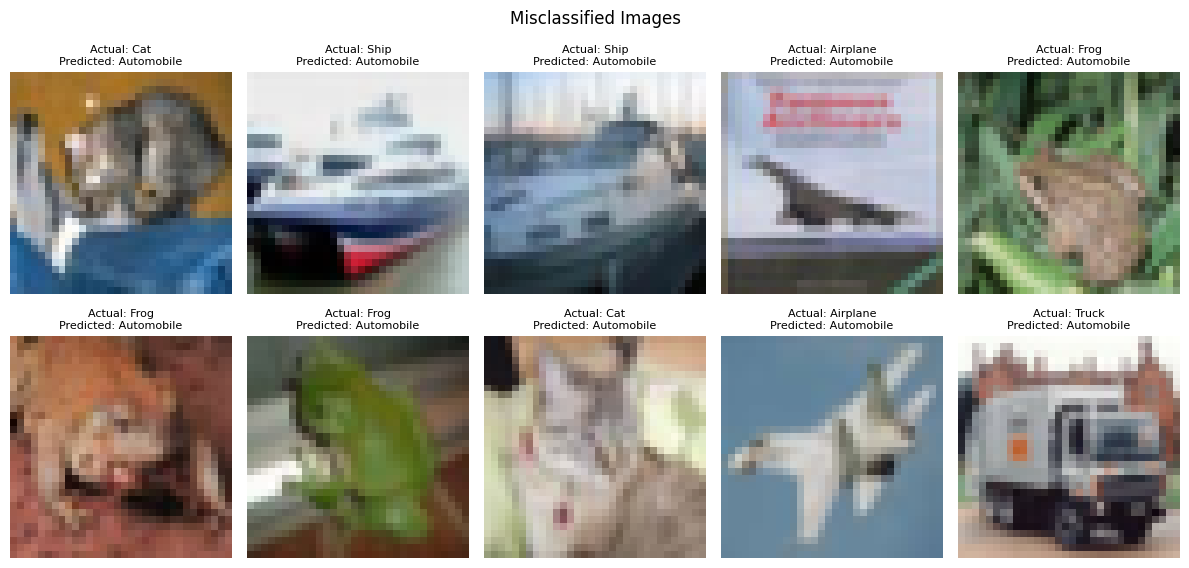

Total Incorrect Predictions: 9000


In [ ]:
###  35 – Visualize Misclassified Images



wrong_indices = np.where(
    mobilenet_predicted_labels != actual_labels
)[0]

plt.figure(figsize=(12, 6))

for i, idx in enumerate(wrong_indices[:10]):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[idx])

    plt.title(
        f"Actual: {class_names[actual_labels[idx]]}\n"
        f"Predicted: {class_names[mobilenet_predicted_labels[idx]]}",
        fontsize=8
    )

    plt.axis('off')

plt.suptitle("Misclassified Images")
plt.tight_layout()
plt.show()

print("Total Incorrect Predictions:", len(wrong_indices))

In [ ]:
###  36 – Calculate Model Accuracy

cnn_final_accuracy = accuracy_score(
    actual_labels,
    cnn_predicted_labels
)

mobile_final_accuracy = accuracy_score(
    actual_labels,
    mobilenet_predicted_labels
)

print("CNN Accuracy:", round(cnn_final_accuracy * 100, 2), "%")

print(
    "MobileNetV2 Accuracy:",
    round(mobile_final_accuracy * 100, 2),
    "%"
)

CNN Accuracy: 74.05 %
MobileNetV2 Accuracy: 10.0 %


**TASK 5 – MODEL ANALYSIS AND DOCUMENTATION**

In [ ]:

###  37 – CNN vs MobileNetV2 Performance Analysis


print("MODEL PERFORMANCE ANALYSIS")
print("=" * 40)

print("CNN Accuracy:",
      round(cnn_final_accuracy * 100, 2), "%")

print("MobileNetV2 Accuracy:",
      round(mobile_final_accuracy * 100, 2), "%")

if mobile_final_accuracy > cnn_final_accuracy:
    print("\nMobileNetV2 performed better than CNN.")
elif mobile_final_accuracy < cnn_final_accuracy:
    print("\nCNN performed better than MobileNetV2.")
else:
    print("\nBoth models achieved equal accuracy.")

MODEL PERFORMANCE ANALYSIS
CNN Accuracy: 74.05 %
MobileNetV2 Accuracy: 10.0 %

CNN performed better than MobileNetV2.


In [ ]:
### 38 – Model Comparison Table


analysis = pd.DataFrame({
    'Features': [
        'Architecture',
        'Pretrained Weights',
        'Training Time',
        'Feature Extraction',
        'Performance'
    ],
    'Custom CNN': [
        'Built from scratch',
        'No',
        'Depends on training',
        'Learns from dataset',
        f'{cnn_final_accuracy * 100:.2f}%'
    ],
    'MobileNetV2': [
        'Pretrained CNN',
        'ImageNet',
        'Depends on training',
        'Uses pretrained features',
        f'{mobile_final_accuracy * 100:.2f}%'
    ]
})

print(analysis.to_string(index=False))

          Features          Custom CNN              MobileNetV2
      Architecture  Built from scratch           Pretrained CNN
Pretrained Weights                  No                 ImageNet
     Training Time Depends on training      Depends on training
Feature Extraction Learns from dataset Uses pretrained features
       Performance              74.05%                   10.00%


In [ ]:
### 39 – Save CNN Model


cnn_model.save("cifar10_cnn_model.keras")

print("CNN model saved successfully!")

CNN model saved successfully!


In [ ]:
###  40 – Save MobileNetV2 Model



mobilenet_model.save("cifar10_mobilenetv2_model.keras")

print("MobileNetV2 model saved successfully!")

MobileNetV2 model saved successfully!


In [ ]:
### 41 – Save Training Results

results = pd.DataFrame({
    'Model': ['CNN', 'MobileNetV2'],
    'Accuracy': [
        cnn_final_accuracy,
        mobile_final_accuracy
    ],
    'Loss': [
        cnn_loss,
        mobilenet_loss
    ]
})

results.to_csv("model_results.csv", index=False)

print(results)
print("\nResults saved successfully!")

         Model  Accuracy      Loss
0          CNN    0.7405  0.781928
1  MobileNetV2    0.1000  2.302623

Results saved successfully!


In [ ]:
### 42 – Final Project Conclusion

print("=" * 55)
print("AI-BASED IMAGE CLASSIFICATION SYSTEM")
print("=" * 55)

print("Dataset: CIFAR-10")
print("Number of Classes: 10")
print("Custom Model: CNN")
print("Transfer Learning Model: MobileNetV2")

print("\nCNN Accuracy:",
      round(cnn_final_accuracy * 100, 2), "%")

print("MobileNetV2 Accuracy:",
      round(mobile_final_accuracy * 100, 2), "%")

print("\nProject completed successfully!")

AI-BASED IMAGE CLASSIFICATION SYSTEM
Dataset: CIFAR-10
Number of Classes: 10
Custom Model: CNN
Transfer Learning Model: MobileNetV2

CNN Accuracy: 74.05 %
MobileNetV2 Accuracy: 10.0 %

Project completed successfully!
